In [8]:
gpu_info = !nvidia-smi
gpu_info = '\n'.join(gpu_info)
if gpu_info.find('failed') >= 0:
  print('Not connected to a GPU')
else:
  print(gpu_info)

Fri Apr 25 00:56:34 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             45W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [9]:
from psutil import virtual_memory
ram_gb = virtual_memory().total / 1e9
print('Your runtime has {:.1f} gigabytes of available RAM\n'.format(ram_gb))

if ram_gb < 20:
  print('Not using a high-RAM runtime')
else:
  print('You are using a high-RAM runtime!')

Your runtime has 89.6 gigabytes of available RAM

You are using a high-RAM runtime!


In [10]:
import pandas as pd
import ast
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import math
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [14]:
df = pd.read_csv('/content/train_and_validate.csv')

In [12]:
df_90 = df.sample(frac=0.9, random_state=100)
df_10 = df.drop(df_90.index)

In [7]:
df_90.to_csv('train_and_validate.csv', index=False)
df_10.to_csv('test.csv', index=False)

In [5]:
df.shape

(13484, 4)

In [5]:
from scipy.stats import percentileofscore

lengths = df['sequence'].str.len()
percentile = percentileofscore(lengths, 2500, kind='rank')
print(f"2500 is at the {percentile:.2f} percentile.")


2500 is at the 98.61 percentile.


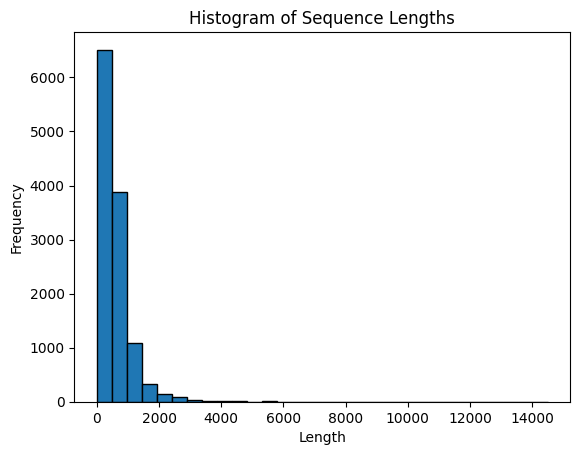

In [15]:
lengths = df['sequence'].str.len()

plt.hist(lengths, bins=30, edgecolor='black')
plt.title('Histogram of Sequence Lengths')
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.show()

In [16]:
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"
PAD_TOKEN = "<pad>"
AA_TO_IDX = {aa: idx for idx, aa in enumerate(AMINO_ACIDS)}
AA_TO_IDX[PAD_TOKEN] = len(AA_TO_IDX)
IDX_TO_AA = {idx: aa for aa, idx in AA_TO_IDX.items()}
VOCAB_SIZE = len(AA_TO_IDX)

EMBEDDING_DIM = 256
NHEAD = 8
NUM_ENCODER_LAYERS = 4
DIM_FEEDFORWARD = 1024
DROPOUT_RATE = 0.05
MAX_SEQ_LEN = 2500
BATCH_SIZE = 128
NUM_EPOCHS = 40
LEARNING_RATE = 0.0003

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [17]:
class ProteinLocalizationDataset(Dataset):
    def __init__(self, dataframe, aa_to_idx, pad_token, max_seq_len=None):
        self.dataframe = dataframe
        self.aa_to_idx = aa_to_idx
        self.pad_idx = aa_to_idx[pad_token]
        self.max_seq_len = max_seq_len if max_seq_len is not None else self._determine_max_seq_len()

        self.unique_locations = sorted(dataframe['location'].unique())
        self.location_to_idx = {loc: idx for idx, loc in enumerate(self.unique_locations)}
        self.idx_to_location = {idx: loc for loc, idx in self.location_to_idx.items()}
        self.num_locations = len(self.unique_locations)

    def _determine_max_seq_len(self):
        return self.dataframe['sequence'].str.len().max()

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        seq_str = self.dataframe.iloc[idx]['sequence']
        location_str = self.dataframe.iloc[idx]['location']

        seq_indices = [self.aa_to_idx.get(aa, self.pad_idx) for aa in seq_str]

        original_length = len(seq_indices)

        if original_length > self.max_seq_len:
             seq_indices = seq_indices[:self.max_seq_len]
             original_length = self.max_seq_len
        else:
             padding_length = self.max_seq_len - original_length
             seq_indices.extend([self.pad_idx] * padding_length)

        seq_tensor = torch.tensor(seq_indices, dtype=torch.long)
        length_tensor = torch.tensor(original_length, dtype=torch.long)
        location_tensor = torch.tensor(self.location_to_idx[location_str], dtype=torch.long)

        return seq_tensor, length_tensor, location_tensor


In [18]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:x.size(0), :]
        return self.dropout(x)

In [19]:
class ProteinTransformer(nn.Module):
    def __init__(self, vocab_size, embedding_dim, nhead, num_encoder_layers,
                 dim_feedforward, dropout, num_classes, max_seq_len, pad_idx):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.pos_encoder = PositionalEncoding(embedding_dim, dropout, max_len=max_seq_len) # Adjusted max_len for PE

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=False
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)

        self.pooling = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Linear(embedding_dim, num_classes)

        self.pad_idx = pad_idx
        self.max_seq_len = max_seq_len


    def forward(self, src, src_lengths):
        src = self.embedding(src)

        src = src.transpose(0, 1)

        src = self.pos_encoder(src)

        batch_size, seq_len = src.shape[1], src.shape[0]
        mask = torch.arange(seq_len).unsqueeze(0).expand(batch_size, -1).to(DEVICE) >= src_lengths.unsqueeze(1)

        transformer_output = self.transformer_encoder(src, src_key_padding_mask=mask)

        pooled_output = self.pooling(transformer_output.permute(1, 2, 0))
        pooled_output = pooled_output.squeeze(-1)

        logits = self.classifier(pooled_output)

        return logits


In [22]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs, device):
    model.to(device)

    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []

    best_val_loss = float('inf')
    epochs_without_improvement = 0
    patience = scheduler.patience
    best_model_state = None


    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for i, (sequences, lengths, labels) in enumerate(train_loader):
            sequences, lengths, labels = sequences.to(device), lengths.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(sequences, lengths)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

            if (i + 1) % 10 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], Train Loss: {loss.item():.4f}')

        train_accuracy = 100 * correct_train / total_train
        avg_train_loss = running_loss/len(train_loader)
        print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')

        train_losses.append(avg_train_loss)
        train_accuracies.append(train_accuracy)

        model.eval()
        running_loss_val = 0.0
        correct_val = 0
        total_val = 0
        with torch.no_grad():
            for sequences_val, lengths_val, labels_val in val_loader:
                sequences_val, lengths_val, labels_val = sequences_val.to(device), lengths_val.to(device), labels_val.to(device)

                outputs_val = model(sequences_val, lengths_val)
                loss_val = criterion(outputs_val, labels_val)

                running_loss_val += loss_val.item()
                _, predicted_val = torch.max(outputs_val.data, 1)
                total_val += labels_val.size(0)
                correct_val += (predicted_val == labels_val).sum().item()

        val_accuracy = 100 * correct_val / total_val
        avg_val_loss = running_loss_val/len(val_loader)
        print(f'Epoch [{epoch+1}/{num_epochs}], Validation Loss: {avg_val_loss:.4f}, Validation Accuracy: {val_accuracy:.2f}%')

        val_losses.append(avg_val_loss)
        val_accuracies.append(val_accuracy)

        scheduler.step(avg_val_loss)

        if avg_val_loss < best_val_loss:
             best_val_loss = avg_val_loss
             torch.save(model.state_dict(), 'best_model.pth')
             epochs_without_improvement = 0
             print(f"Validation loss improved. Best loss: {best_val_loss:.4f}")
        else:
             epochs_without_improvement += 1
             print(f"Validation loss did not improve. Patience counter: {epochs_without_improvement}/{patience}")
             if epochs_without_improvement >= patience:
                 print(f"Early stopping triggered after {patience} epochs without validation loss improvement.")
                 break # Exit training loop


    print('Finished Training')

    # --- Plotting the results ---
    epochs_range = range(1, num_epochs + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, label='Training Loss')
    plt.plot(epochs_range, val_losses, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accuracies, label='Training Accuracy')
    plt.plot(epochs_range, val_accuracies, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    plt.show()

In [23]:
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['location'])
test_df = pd.read_csv('/content/test.csv')

In [24]:
train_dataset = ProteinLocalizationDataset(train_df, AA_TO_IDX, PAD_TOKEN, max_seq_len=MAX_SEQ_LEN)
val_dataset = ProteinLocalizationDataset(val_df, AA_TO_IDX, PAD_TOKEN, max_seq_len=MAX_SEQ_LEN)
test_dataset = ProteinLocalizationDataset(test_df, AA_TO_IDX, PAD_TOKEN, max_seq_len=MAX_SEQ_LEN)

In [25]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [26]:
NUM_CLASSES = train_dataset.num_locations
print(f"Number of unique locations: {NUM_CLASSES}")
print(f"Location mapping: {train_dataset.location_to_idx}")

Number of unique locations: 3
Location mapping: {'Cell membrane': 0, 'Cytoplasm': 1, 'Nucleus': 2}


In [27]:
model = ProteinTransformer(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    nhead=NHEAD,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT_RATE,
    num_classes=NUM_CLASSES,
    max_seq_len=MAX_SEQ_LEN,
    pad_idx=AA_TO_IDX[PAD_TOKEN]
)

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


In [28]:
class_counts = train_df['location'].value_counts()
total_count = class_counts.sum()
class_weights = 1. / torch.tensor([class_counts[train_dataset.idx_to_location[i]] for i in range(train_dataset.num_locations)], dtype=torch.float32)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE))
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

In [29]:
scheduler = ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=5,
    verbose=True,
    threshold=0.0001,
    threshold_mode='rel',
    cooldown=0,
    min_lr=1e-6,
    eps=1e-8
)

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [30]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, DEVICE)

Epoch [1/40], Step [10/76], Train Loss: 1.1189
Epoch [1/40], Step [20/76], Train Loss: 0.9510
Epoch [1/40], Step [30/76], Train Loss: 0.9511
Epoch [1/40], Step [40/76], Train Loss: 0.9692
Epoch [1/40], Step [50/76], Train Loss: 0.8749
Epoch [1/40], Step [60/76], Train Loss: 0.8751
Epoch [1/40], Step [70/76], Train Loss: 0.8872
Epoch [1/40], Train Loss: 0.9703, Train Accuracy: 50.58%
Epoch [1/40], Validation Loss: 0.8635, Validation Accuracy: 56.67%
Validation loss improved. Best loss: 0.8635
Epoch [2/40], Step [10/76], Train Loss: 0.8023
Epoch [2/40], Step [20/76], Train Loss: 0.8588
Epoch [2/40], Step [30/76], Train Loss: 0.8834
Epoch [2/40], Step [40/76], Train Loss: 0.9060
Epoch [2/40], Step [50/76], Train Loss: 0.8906
Epoch [2/40], Step [60/76], Train Loss: 0.9350
Epoch [2/40], Step [70/76], Train Loss: 0.8052
Epoch [2/40], Train Loss: 0.8629, Train Accuracy: 56.90%
Epoch [2/40], Validation Loss: 0.8525, Validation Accuracy: 56.88%
Validation loss improved. Best loss: 0.8525
Epoch 

KeyboardInterrupt: 

In [ ]:
def evaluate_on_test(model, test_loader, criterion, device):
    model.to(device)
    model.eval()
    running_loss_test = 0.0
    correct_test = 0
    total_test = 0

    with torch.no_grad():
        for sequences_test, lengths_test, labels_test in test_loader:
            sequences_test, lengths_test, labels_test = sequences_test.to(device), lengths_test.to(device), labels_test.to(device)

            outputs_test = model(sequences_test, lengths_test)
            loss_test = criterion(outputs_test, labels_test)

            running_loss_test += loss_test.item()

            _, predicted_test = torch.max(outputs_test.data, 1)
            total_test += labels_test.size(0)
            correct_test += (predicted_test == labels_test).sum().item()

    avg_test_loss = running_loss_test / len(test_loader) if len(test_loader) > 0 else 0
    test_accuracy = 100 * correct_test / total_test if total_test > 0 else 0

    print(f'\n--- Test Set Results ---')
    print(f'Test Loss: {avg_test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%')
    print(f'------------------------\n')

    return avg_test_loss, test_accuracy


In [ ]:
evaluate_on_test(model, test_loader, criterion, DEVICE)